# Assignment 3 – Parte 2: Mapas

## Pregunta

> **¿Qué regiones del Perú crecieron más entre 2007 y 2019, y tuvo que ver la minería?**

En la Parte 1 respondimos con barras y puntos. Aquí ponemos los mismos números sobre el mapa
para ver si el crecimiento y la minería **se agrupan en alguna zona del país**.

In [1]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import folium

## 1. Los datos: una fila por departamento

`dataset.csv` tiene una fila por departamento y año. Para el mapa necesitamos **una fila por
departamento**, así que calculamos el crecimiento 2007-2019 y nos quedamos con los valores de 2019.

El `ubigeo` se lee como **texto** para no perder el cero de la izquierda (`'01'`, no `1`).

In [2]:
dataset = pd.read_csv("datos/dataset.csv", dtype={"ubigeo": str})
dataset.shape

(312, 9)

In [3]:
# Comprobamos que todos los ubigeos sean texto de 2 dígitos
print(dataset["ubigeo"].dtype, "| ejemplo:", dataset["ubigeo"].iloc[0])
dataset["ubigeo"].str.len().value_counts()

str | ejemplo: 01


ubigeo
2    312
Name: count, dtype: int64

In [4]:
columnas = ["ubigeo", "departamento", "region_natural", "vab_pc", "peso_mineria_pct"]
datos_2007 = dataset[dataset["anio"] == 2007][columnas]
datos_2019 = dataset[dataset["anio"] == 2019][columnas]

tabla = datos_2019.merge(datos_2007[["ubigeo", "vab_pc"]], on="ubigeo", suffixes=("_2019", "_2007"))
tabla["crecimiento_pct"] = ((tabla["vab_pc_2019"] / tabla["vab_pc_2007"] - 1) * 100).round(1)
tabla = tabla.rename(columns={"peso_mineria_pct": "peso_mineria_2019"})

tabla.shape

(24, 7)

In [5]:
tabla.sort_values("crecimiento_pct", ascending=False).head()

,ubigeo,departamento,region_natural,vab_pc_2019,peso_mineria_2019,vab_pc_2007,crecimiento_pct
2,03,APURIMAC,Sierra,16691.6,61.9,4192.4,298.1
8,10,HUANUCO,Sierra,8003.5,7.3,4075.0,96.4
4,05,AYACUCHO,Sierra,8926.4,23.7,4612.0,93.5
6,08,CUSCO,Sierra,16417.4,44.8,8985.0,82.7
7,09,HUANCAVELICA,Sierra,9502.3,12.3,5343.0,77.8


## 2. Las fronteras: GeoJSON departamental de la sesión 7

`datos/departamentos_peru.geojson` es el archivo departamental de la sesión 7 (lo descarga
`fetch_data.py 07-mapas`). Tiene 25 polígonos en `EPSG:4326` (latitud y longitud).

In [6]:
departamentos = gpd.read_file("datos/departamentos_peru.geojson")
print(departamentos.shape)
print(departamentos.crs)
departamentos.head()

(25, 2)
EPSG:4326


,departamento,geometry
0,AMAZONAS,"POLYGON ((-78.03025 -6.7661, -78.04983 -6.6838..."
1,ANCASH,"POLYGON ((-77.69239 -10.3209, -77.75251 -10.32..."
2,APURIMAC,"POLYGON ((-73.51174 -14.53852, -73.52075 -14.5..."
3,AREQUIPA,"POLYGON ((-72.72968 -16.64631, -72.77421 -16.6..."
4,AYACUCHO,"POLYGON ((-74.50188 -15.16058, -74.51267 -15.1..."


### El GeoJSON no trae ubigeo: se lo ponemos

El archivo solo tiene el **nombre** del departamento. Cruzar por nombre es frágil (tildes,
espacios, "LIMA" vs. "LIMA Y CALLAO"), así que le agregamos el **código INEI** de cada
departamento, como texto de 2 dígitos. Lo comprobamos contra el `distritos_peru.geojson` de la
sesión 7, donde los dos primeros dígitos del ubigeo distrital son el del departamento.

In [7]:
codigos_inei = {
    "AMAZONAS": "01", "ANCASH": "02", "APURIMAC": "03", "AREQUIPA": "04", "AYACUCHO": "05",
    "CAJAMARCA": "06", "CALLAO": "07", "CUSCO": "08", "HUANCAVELICA": "09", "HUANUCO": "10",
    "ICA": "11", "JUNIN": "12", "LA LIBERTAD": "13", "LAMBAYEQUE": "14", "LIMA": "15",
    "LORETO": "16", "MADRE DE DIOS": "17", "MOQUEGUA": "18", "PASCO": "19", "PIURA": "20",
    "PUNO": "21", "SAN MARTIN": "22", "TACNA": "23", "TUMBES": "24", "UCAYALI": "25",
}
departamentos["ubigeo"] = departamentos["departamento"].map(codigos_inei)

# Si algún nombre no estuviera en el diccionario, quedaría vacío
print("Departamentos sin código:", departamentos["ubigeo"].isna().sum())
print(departamentos["ubigeo"].dtype, "| ejemplo:", departamentos["ubigeo"].iloc[0])

Departamentos sin código: 0
str | ejemplo: 01


## 3. Cruzar por ubigeo y reportar lo que no cruza

Antes del merge revisamos qué códigos están en un lado y no en el otro. `indicator=True` agrega
la columna `_merge`, que dice de dónde vino cada fila.

In [8]:
print("Mapa :", departamentos["ubigeo"].nunique(), "departamentos")
print("Tabla:", tabla["ubigeo"].nunique(), "departamentos")
print("Coinciden:", len(set(departamentos["ubigeo"]) & set(tabla["ubigeo"])))

prueba = departamentos.merge(tabla, on="ubigeo", how="outer", indicator=True)
prueba["_merge"].value_counts()

Mapa : 25 departamentos
Tabla: 24 departamentos
Coinciden: 24


_merge
both          24
left_only      1
right_only     0
Name: count, dtype: int64

In [9]:
# Lo que no cruzó
prueba[prueba["_merge"] != "both"][["ubigeo", "departamento_x", "departamento_y", "_merge"]]

,ubigeo,departamento_x,departamento_y,_merge
6,07,CALLAO,NaN,left_only


**No cruzó un solo polígono: el Callao (`'07'`).** No es un error. En nuestros datos, Lima y
Callao van juntos con `ubigeo = '15'` (el INEI publica el VAB de Lima con la producción del Callao
incluida; ver Parte 1). Si lo dejáramos así, el Callao saldría en blanco en el mapa.

Solución: le cambiamos el código al Callao por `'15'` y **unimos los dos polígonos** en uno solo
con `.dissolve()`.

In [10]:
departamentos.loc[departamentos["ubigeo"] == "07", "ubigeo"] = "15"
departamentos = departamentos.dissolve(by="ubigeo", as_index=False)
departamentos = departamentos[["ubigeo", "geometry"]]

departamentos.shape

(24, 2)

In [11]:
mapa = departamentos.merge(tabla, on="ubigeo", how="outer", indicator=True)
print(mapa["_merge"].value_counts())
print("Sin cruzar:", (mapa["_merge"] != "both").sum())

_merge
both          24
left_only      0
right_only     0
Name: count, dtype: int64
Sin cruzar: 0


Ahora los 24 departamentos cruzan y no sobra ninguno.

### ¿El cruce cambió algún número?

Comparamos un total antes y después del merge: si coinciden, no perdimos ni duplicamos filas.

In [12]:
mapa = mapa.drop(columns="_merge")

print("Suma de VAB per cápita 2019, tabla:", round(tabla["vab_pc_2019"].sum(), 1))
print("Suma de VAB per cápita 2019, mapa :", round(mapa["vab_pc_2019"].sum(), 1))

Suma de VAB per cápita 2019, tabla: 340359.0
Suma de VAB per cápita 2019, mapa : 340359.0


## 4. Mapas estáticos con Geopandas

Para que los cuatro mapas se vean igual (y nítidos), usamos una función que recibe la columna,
los colores y los textos. Los mapas se dibujan en alta resolución (`retina`) y con el nombre de
cada departamento.

In [13]:
import matplotlib.patheffects as pe

%config InlineBackend.figure_format = "retina"

fuente = "Fuente: INEI, VAB por departamentos (soles de 2007) y estimaciones de población. Elaboración propia."

# Un punto dentro de cada departamento para poner su nombre
etiquetas = mapa.copy()
etiquetas["punto"] = etiquetas.representative_point()
etiquetas["nombre"] = etiquetas["departamento"].str.title().str.replace(" Y ", " y ").str.replace(" De ", " de ")

# Correr un poco (en grados) los nombres que se chocan con el vecino
ajustes = {"CAJAMARCA": (0.3, 0.5), "LIMA Y CALLAO": (-0.6, 0.0), "JUNIN": (0.4, 0.0)}
for nombre, (dx, dy) in ajustes.items():
    fila = etiquetas["departamento"] == nombre
    etiquetas.loc[fila, "punto"] = etiquetas.loc[fila, "punto"].translate(dx, dy)


def dibujar_mapa(columna, colores, titulo, subtitulo, leyenda, formato="{:.0f}", cuantiles=True):
    fig, ax = plt.subplots(figsize=(8, 10.5))

    opciones = dict(column=columna, cmap=colores, edgecolor="white", linewidth=0.6, ax=ax, legend=True)
    if cuantiles:
        opciones.update(scheme="quantiles", k=5,
                        legend_kwds={"loc": "lower left", "fontsize": 10, "title_fontsize": 10,
                                     "fmt": formato, "title": leyenda, "frameon": False})
    else:
        opciones.update(legend_kwds={"label": leyenda, "shrink": 0.5, "pad": 0.01})
    mapa.plot(**opciones)

    for _, fila in etiquetas.iterrows():
        ax.annotate(fila["nombre"], xy=(fila["punto"].x, fila["punto"].y),
                    ha="center", va="center", fontsize=7.5, color="#222222",
                    path_effects=[pe.withStroke(linewidth=2.5, foreground="white")])

    ax.set_axis_off()
    fig.suptitle(titulo, x=0.06, y=0.985, ha="left", va="top", fontsize=15, fontweight="bold")
    fig.text(0.06, 0.925, subtitulo, ha="left", va="top", fontsize=11, color="#555555")
    fig.text(0.06, 0.03, fuente, ha="left", fontsize=8, color="gray")
    fig.subplots_adjust(top=0.89, bottom=0.05, left=0.02, right=0.98)
    plt.show()

### El problema de Apurímac

Si pintamos el crecimiento con una escala continua, Apurímac (+298 %) es tan extremo que
todo lo demás queda casi del mismo color.

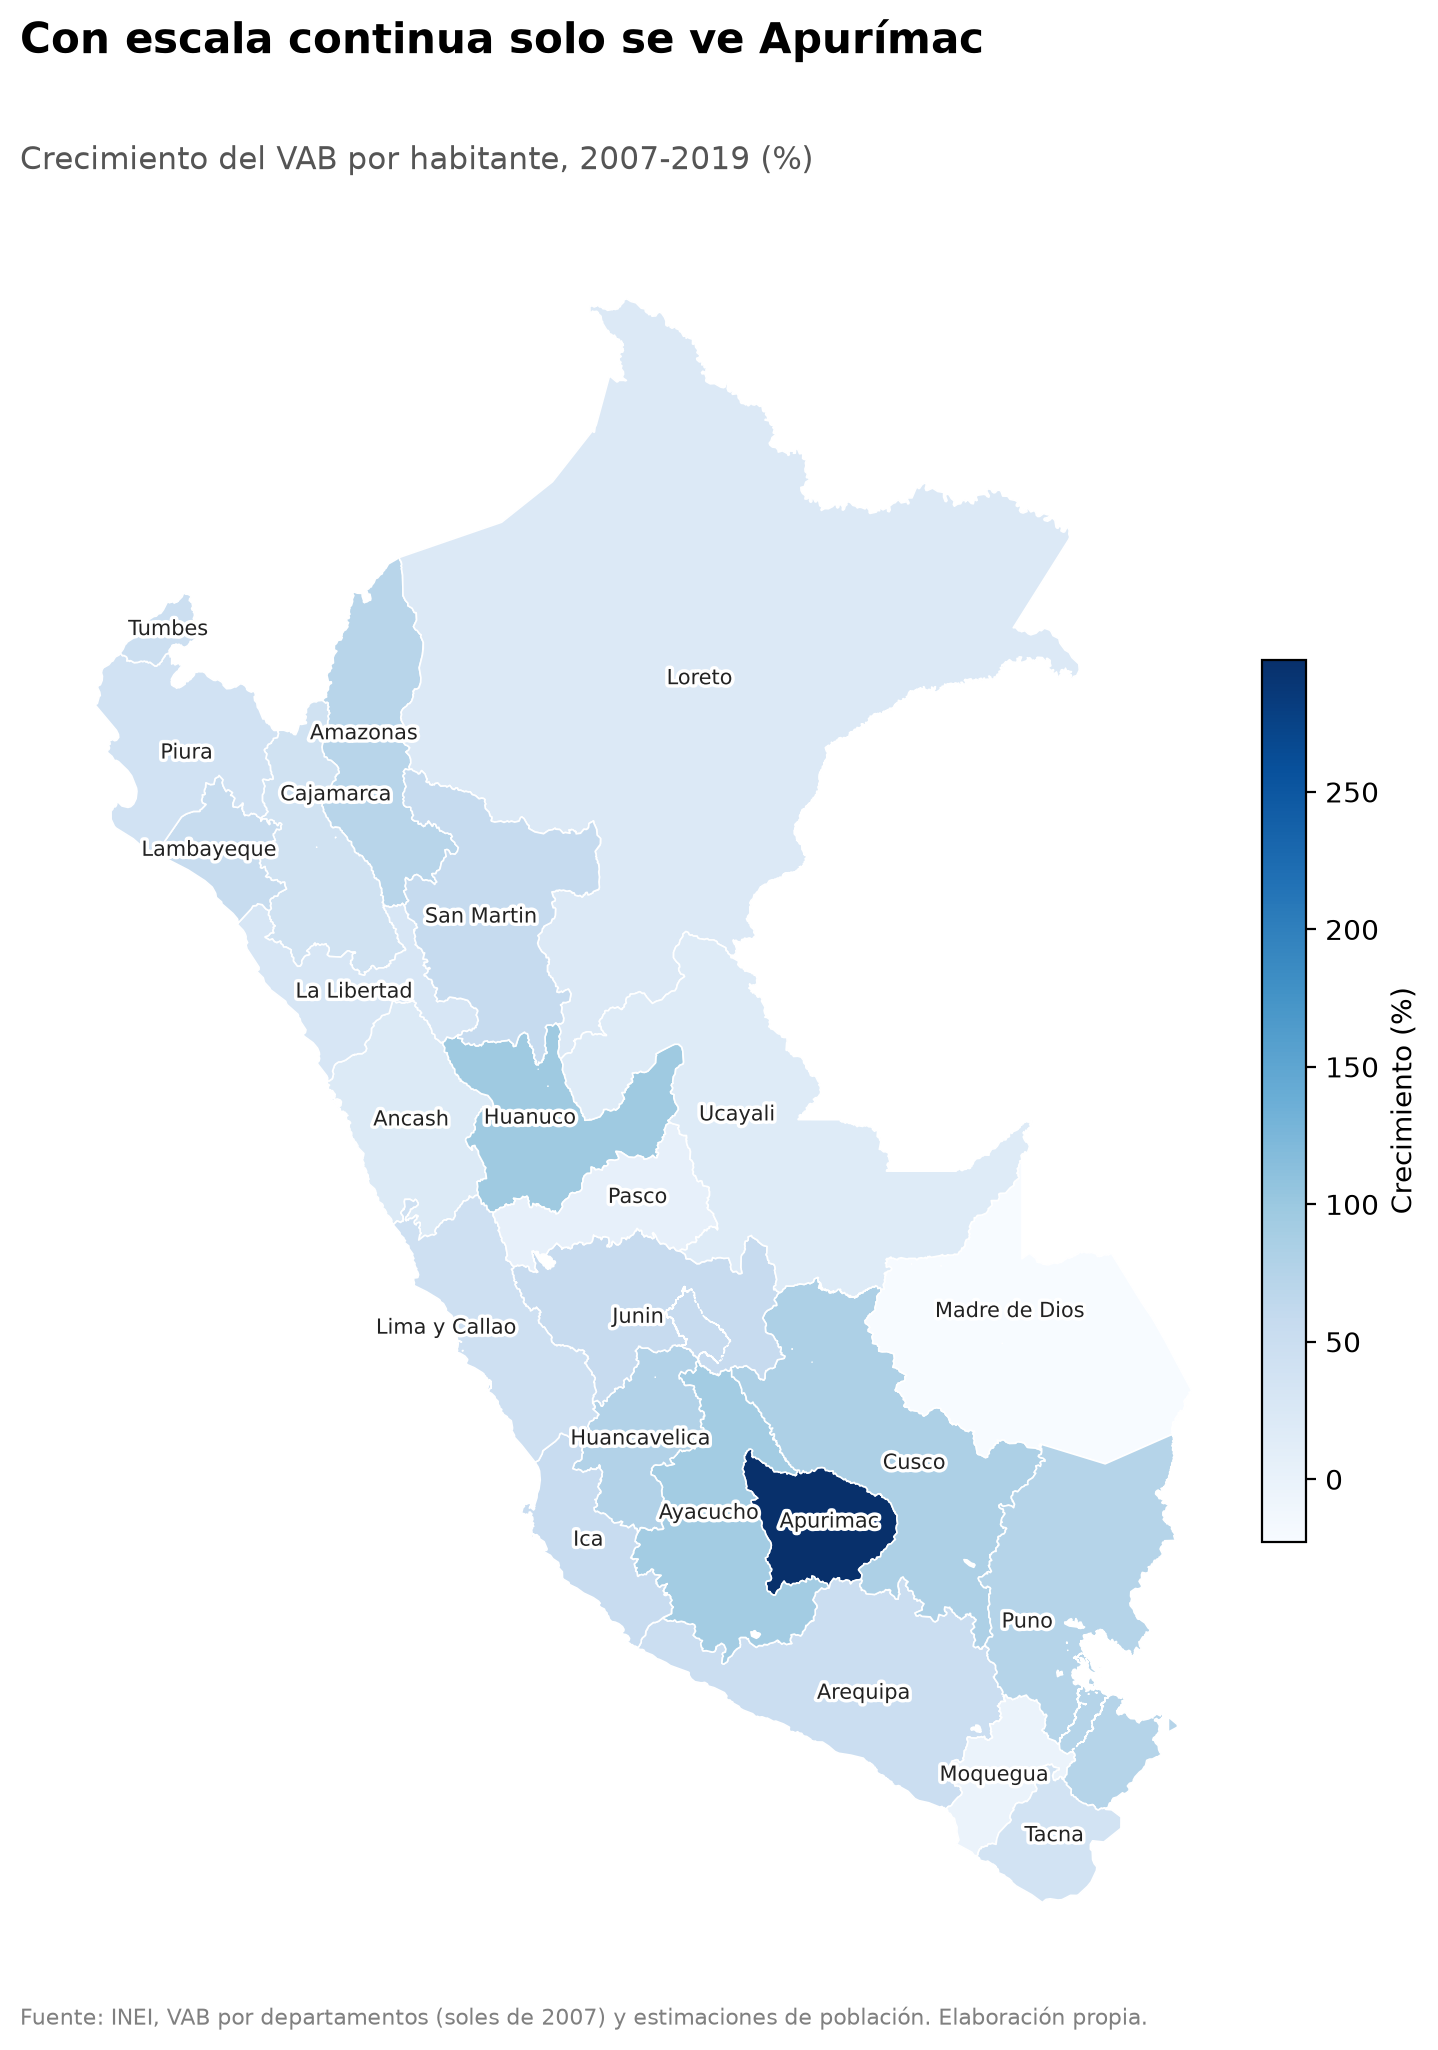

In [14]:
dibujar_mapa("crecimiento_pct", "Blues",
             titulo="Con escala continua solo se ve Apurímac",
             subtitulo="Crecimiento del VAB por habitante, 2007-2019 (%)",
             leyenda="Crecimiento (%)", cuantiles=False)

### Mapa 1: crecimiento, por cuantiles

Con `scheme="quantiles"` los 24 departamentos se reparten en 5 grupos de casi el mismo tamaño,
y el mapa vuelve a mostrar diferencias.

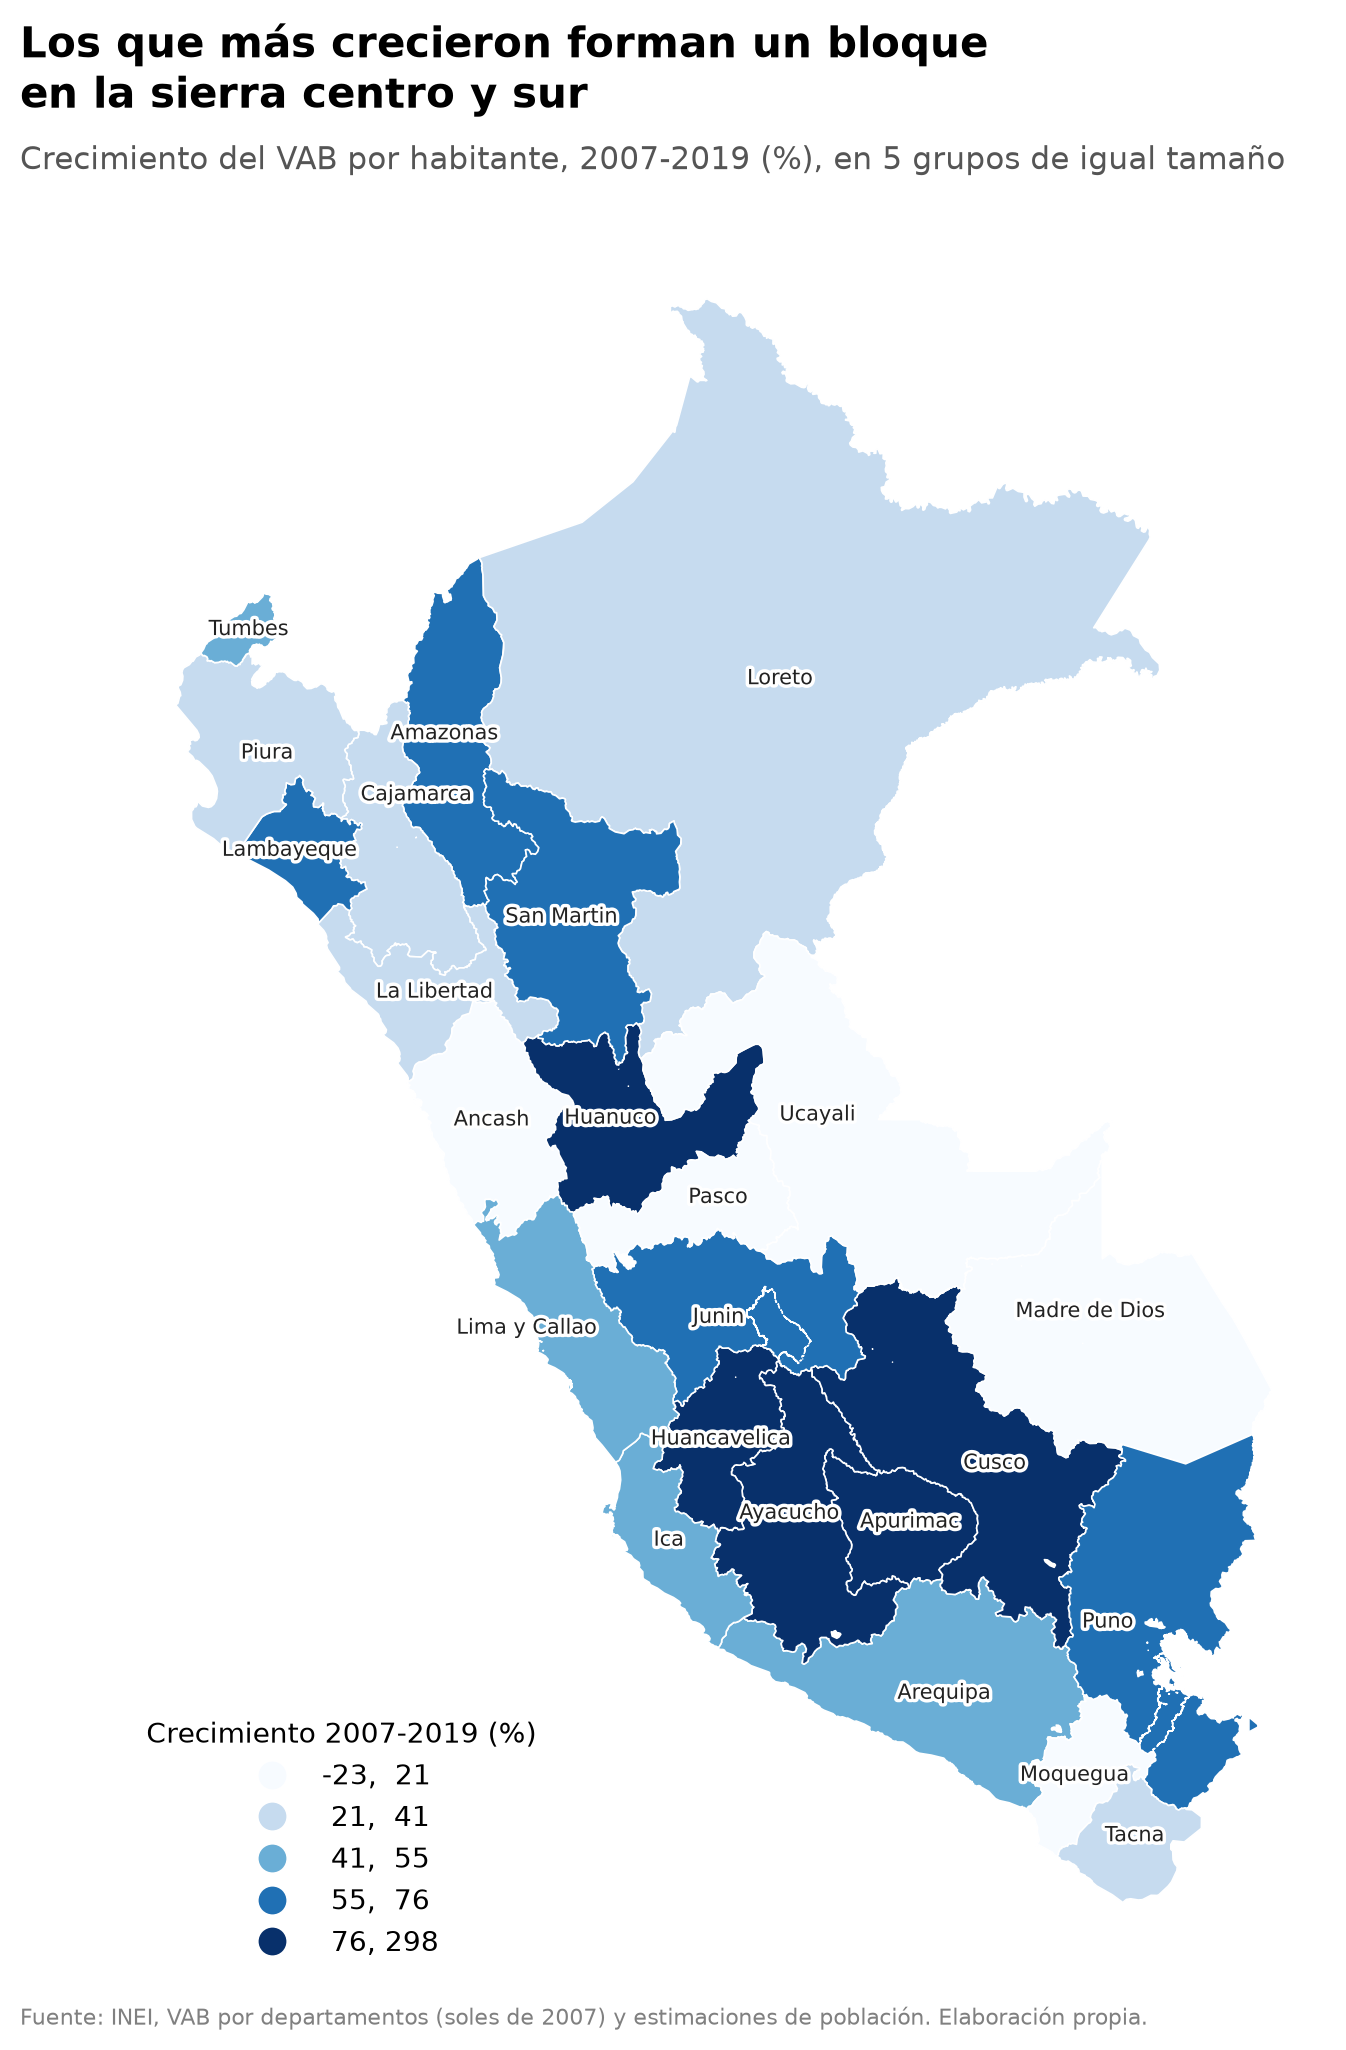

In [15]:
dibujar_mapa("crecimiento_pct", "Blues",
             titulo="Los que más crecieron forman un bloque\nen la sierra centro y sur",
             subtitulo="Crecimiento del VAB por habitante, 2007-2019 (%), en 5 grupos de igual tamaño",
             leyenda="Crecimiento 2007-2019 (%)")

### Mapa 2: peso de la minería, por cuantiles

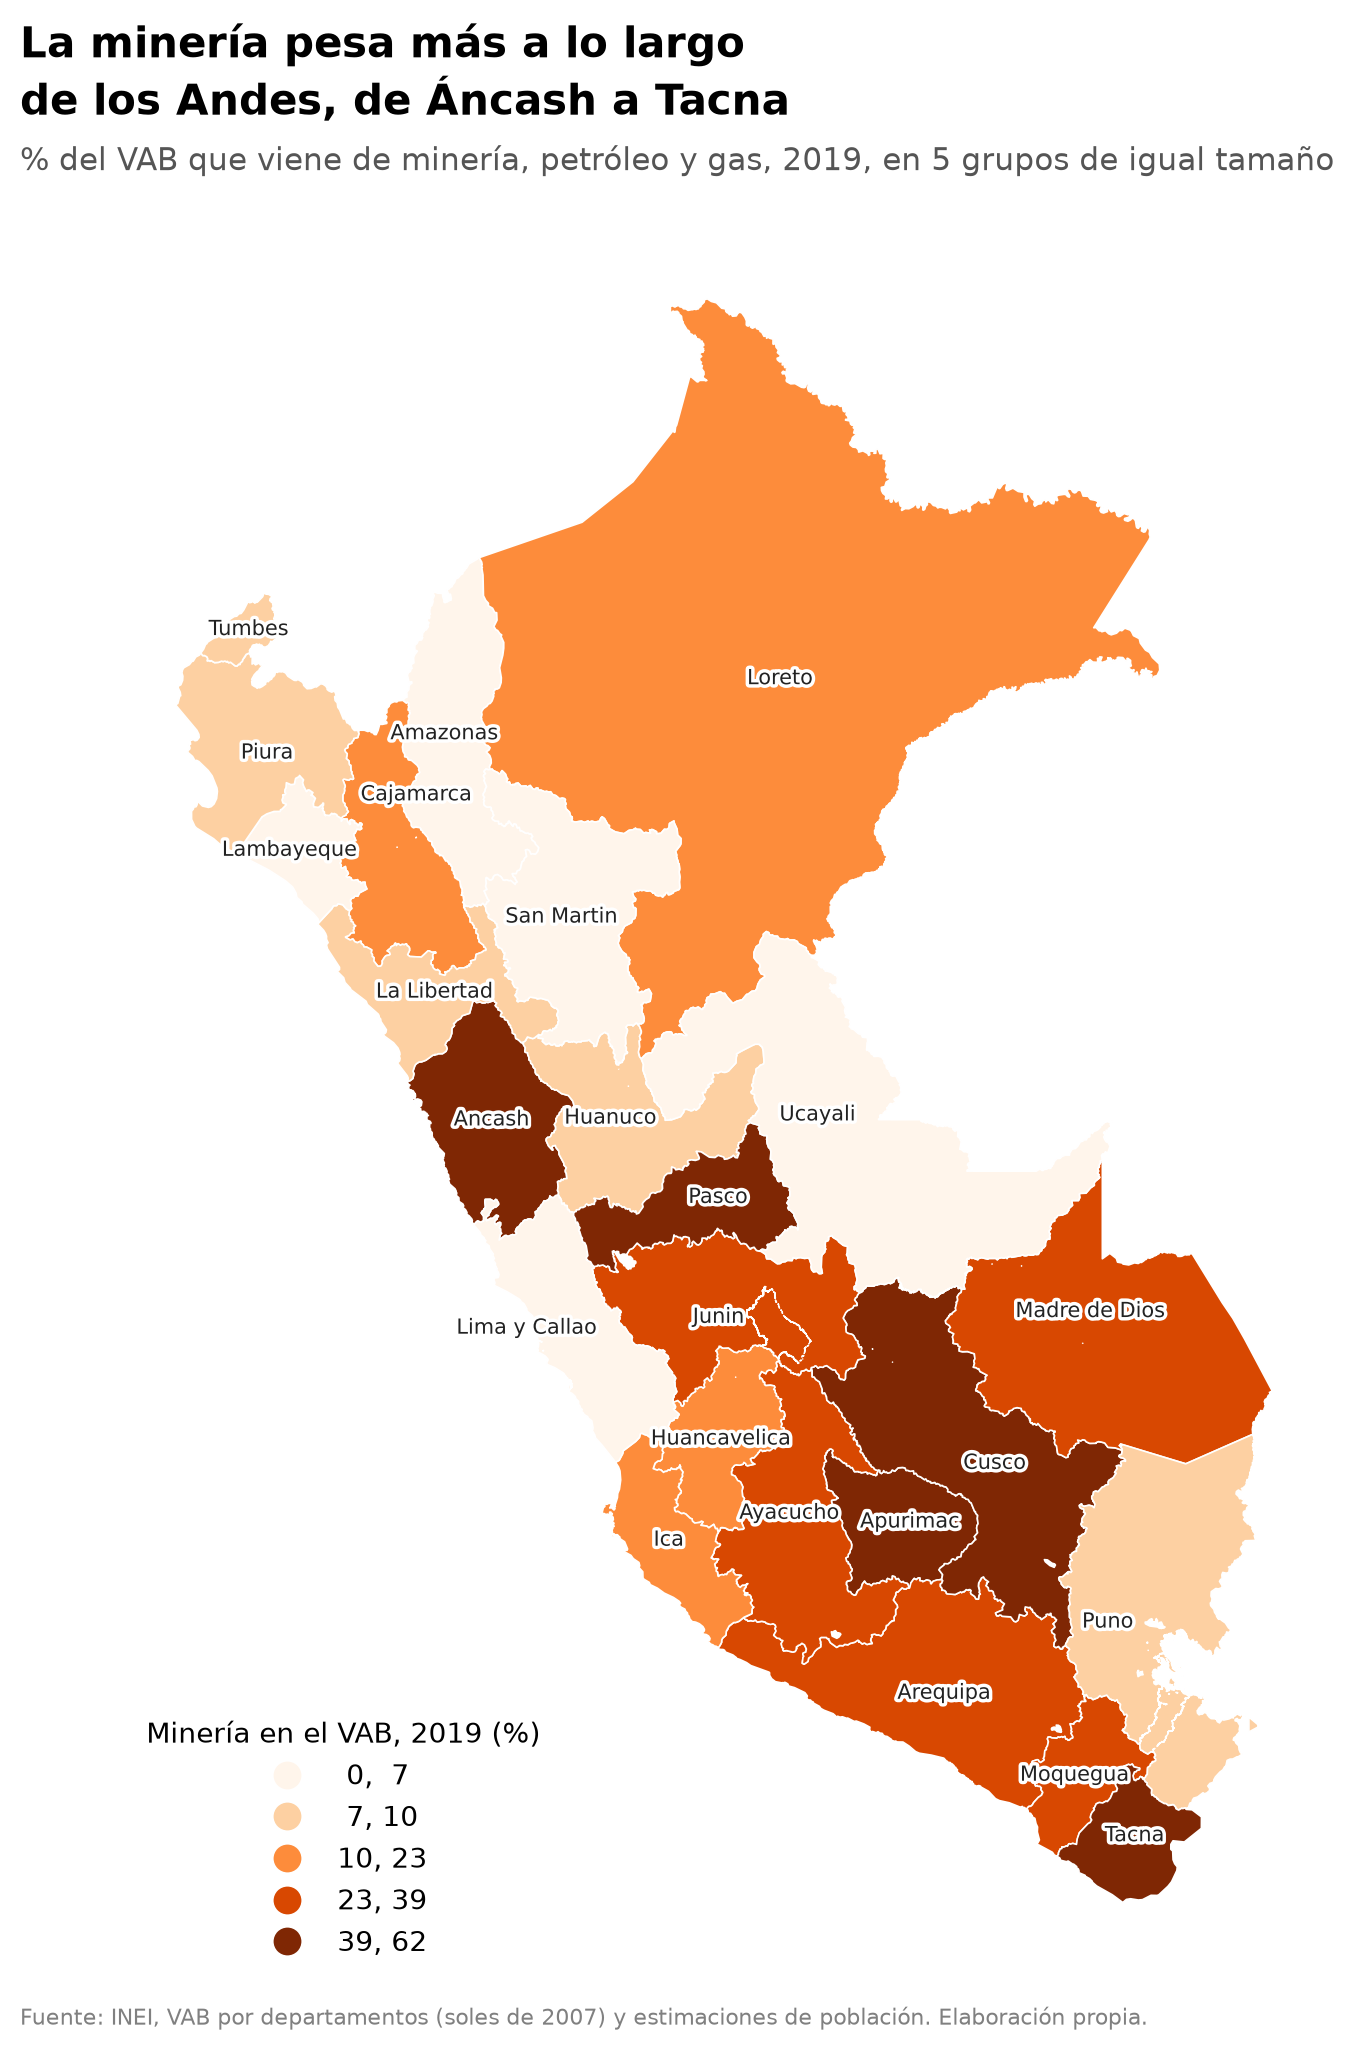

In [16]:
dibujar_mapa("peso_mineria_2019", "Oranges",
             titulo="La minería pesa más a lo largo\nde los Andes, de Áncash a Tacna",
             subtitulo="% del VAB que viene de minería, petróleo y gas, 2019, en 5 grupos de igual tamaño",
             leyenda="Minería en el VAB, 2019 (%)")

### Mapa 3: VAB por habitante en 2019, por cuantiles

Crecer mucho no es lo mismo que producir mucho. Este mapa muestra el **nivel** en 2019.

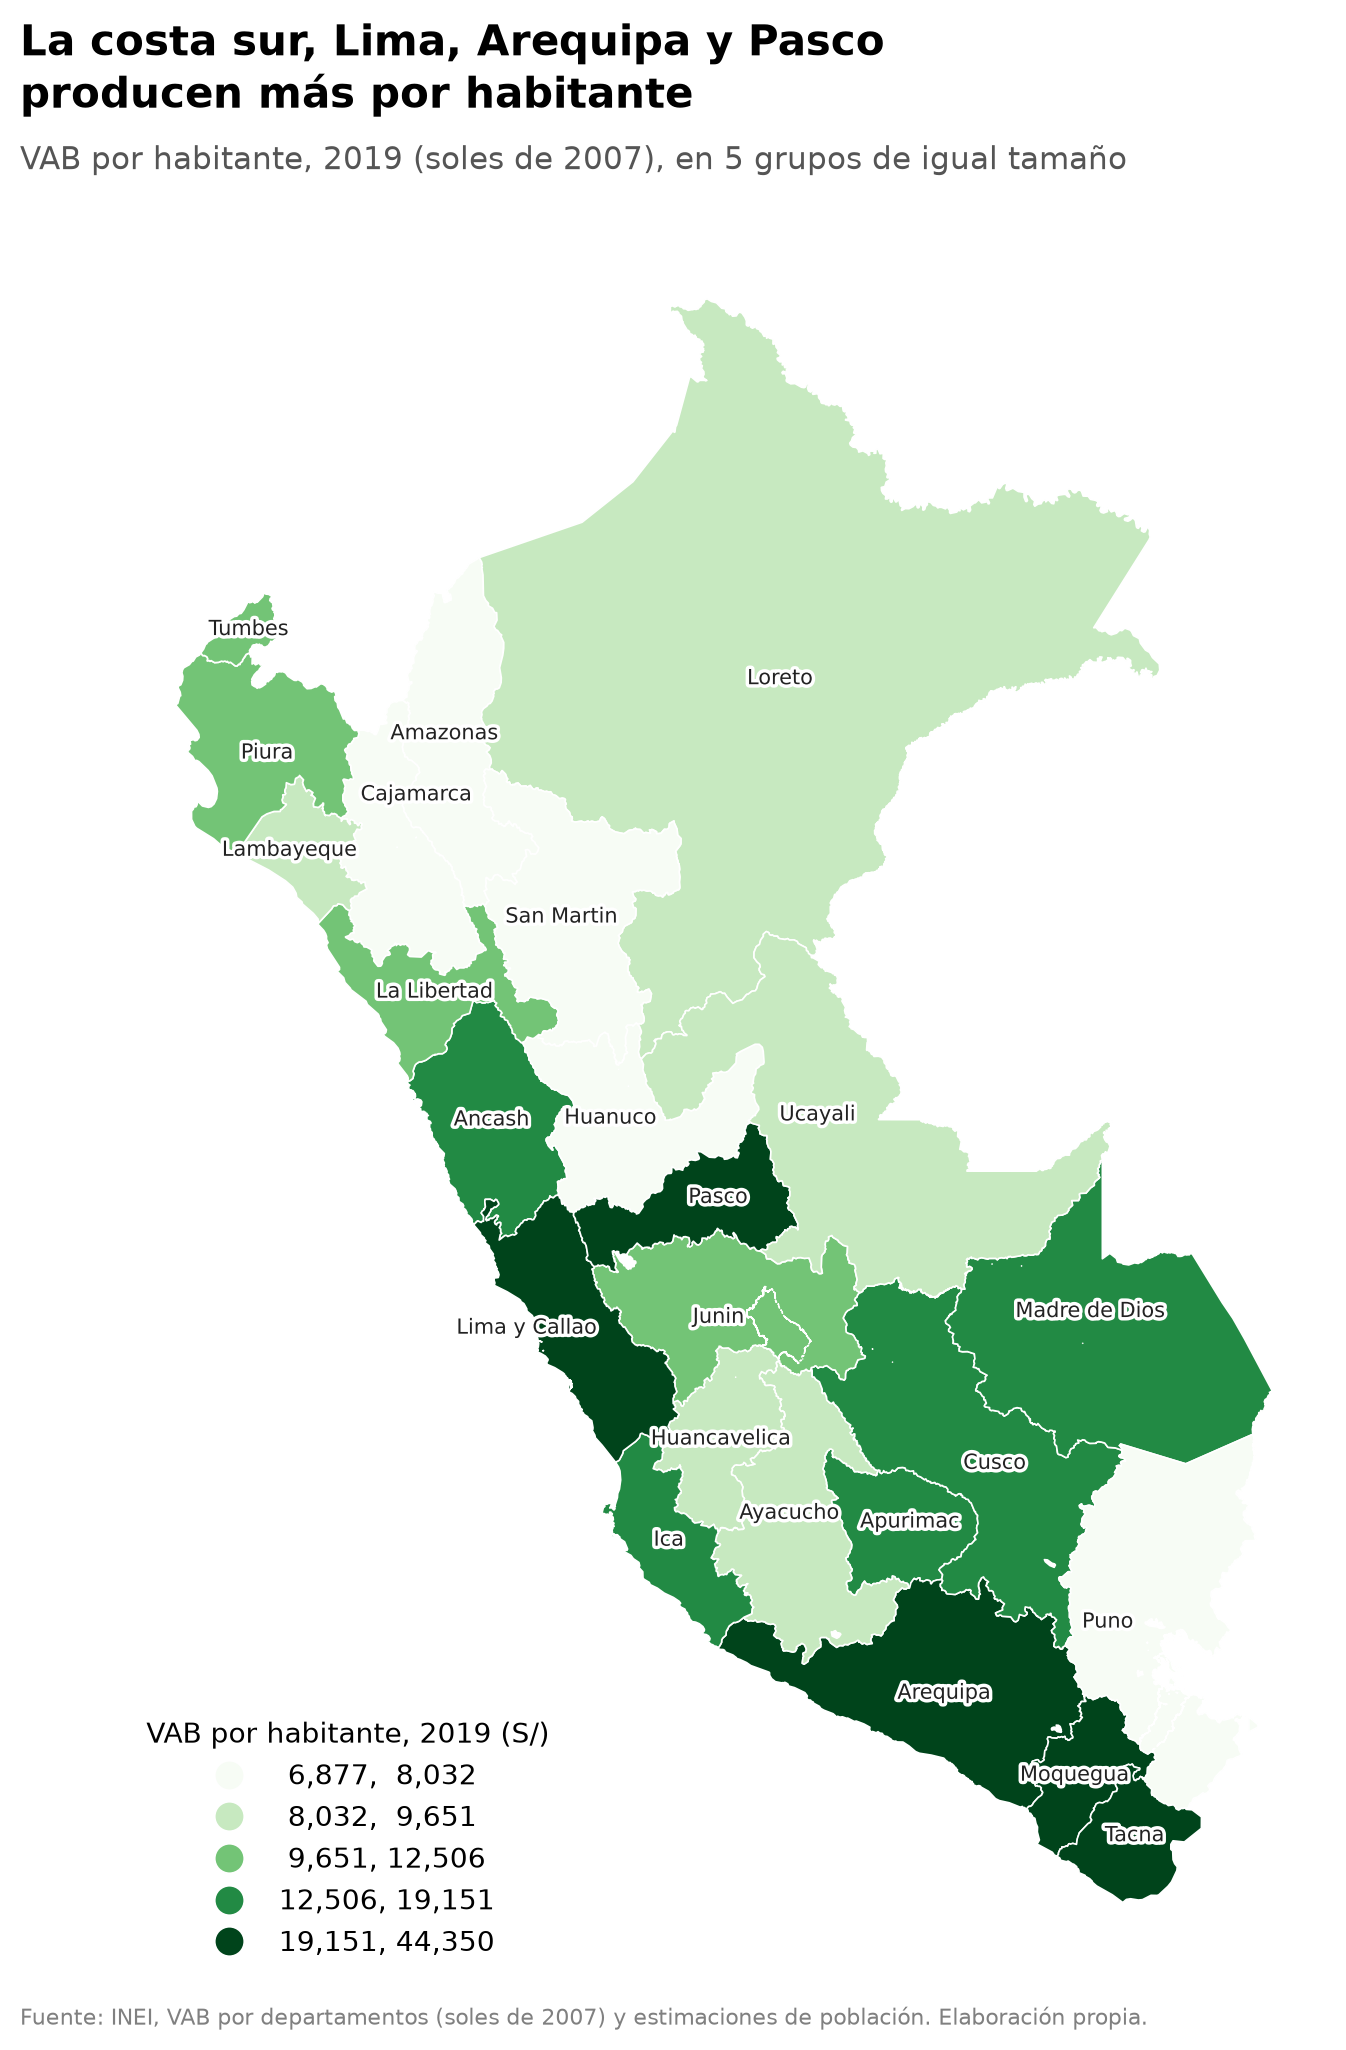

In [17]:
dibujar_mapa("vab_pc_2019", "Greens",
             titulo="La costa sur, Lima, Arequipa y Pasco\nproducen más por habitante",
             subtitulo="VAB por habitante, 2019 (soles de 2007), en 5 grupos de igual tamaño",
             leyenda="VAB por habitante, 2019 (S/)", formato="{:,.0f}")

### Verificación: ¿el mapa dice lo mismo que la tabla?

Los departamentos del quintil más alto deberían ser los más oscuros en cada mapa.

In [18]:
columnas = ["departamento", "region_natural", "crecimiento_pct", "peso_mineria_2019", "vab_pc_2019"]
mapa.sort_values("crecimiento_pct", ascending=False)[columnas].head(5)

,departamento,region_natural,crecimiento_pct,peso_mineria_2019,vab_pc_2019
2,APURIMAC,Sierra,298.1,61.9,16691.6
8,HUANUCO,Sierra,96.4,7.3,8003.5
4,AYACUCHO,Sierra,93.5,23.7,8926.4
6,CUSCO,Sierra,82.7,44.8,16417.4
7,HUANCAVELICA,Sierra,77.8,12.3,9502.3


In [19]:
mapa.sort_values("crecimiento_pct")[columnas].head(5)

,departamento,region_natural,crecimiento_pct,peso_mineria_2019,vab_pc_2019
15,MADRE DE DIOS,Selva,-22.7,25.5,12673.3
16,MOQUEGUA,Costa,-2.9,26.6,44350.3
17,PASCO,Sierra,4.1,58.0,20002.7
23,UCAYALI,Selva,17.5,5.6,8050.6
1,ANCASH,Sierra,20.0,45.1,17151.5


In [20]:
mapa.sort_values("peso_mineria_2019", ascending=False)[columnas].head(5)

,departamento,region_natural,crecimiento_pct,peso_mineria_2019,vab_pc_2019
2,APURIMAC,Sierra,298.1,61.9,16691.6
17,PASCO,Sierra,4.1,58.0,20002.7
21,TACNA,Costa,38.0,45.4,24056.6
1,ANCASH,Sierra,20.0,45.1,17151.5
6,CUSCO,Sierra,82.7,44.8,16417.4


In [21]:
# Mediana por región natural
mapa.groupby("region_natural")[["crecimiento_pct", "peso_mineria_2019", "vab_pc_2019"]].median().round(1)

,crecimiento_pct,peso_mineria_2019,vab_pc_2019
region_natural,,,
Costa,42.1,8.7,15209.2
Selva,22.0,5.6,8050.6
Sierra,74.6,27.1,11355.7


Coincide: los cinco que más crecieron (Apurímac, Huánuco, Ayacucho, Cusco, Huancavelica) son
de la sierra y están juntos en el centro-sur del mapa. En el grupo más claro quedan dos de la
selva (Madre de Dios, Ucayali), dos mineros de la sierra (Pasco, Áncash) y Moquegua. Los de más
minería (Apurímac, Pasco, Tacna, Áncash, Cusco) siguen la cordillera; Loreto aparece en un tono
medio porque la "minería" del INEI incluye su petróleo.

## 5. Mapa interactivo con Folium

`folium.Choropleth` pinta los colores y una capa `GeoJson` encima muestra los datos al pasar el
mouse. Usamos los mismos cortes por cuantiles que en el Mapa 1.

> Este mapa **no se guarda con su salida** en el notebook porque pesa varios MB. Se genera al
> correr la celda.

In [22]:
# Cortes por quintiles (los mismos 5 grupos del Mapa 1)
cortes = mapa["crecimiento_pct"].quantile([0, 0.2, 0.4, 0.6, 0.8, 1]).tolist()
cortes[0] = cortes[0] - 0.1     # para que el mínimo quede dentro del primer grupo
cortes[-1] = cortes[-1] + 0.1   # y el máximo dentro del último
[round(c, 1) for c in cortes]

[-22.8, 21.2, 41.1, 55.3, 75.9, 298.2]

In [ ]:
m = folium.Map(location=[-9.2, -75.0], zoom_start=5, tiles="cartodbpositron")

folium.Choropleth(
    geo_data=mapa,
    data=mapa,
    columns=["ubigeo", "crecimiento_pct"],
    key_on="feature.properties.ubigeo",
    fill_color="Blues",
    fill_opacity=0.8,
    line_opacity=0.4,
    bins=cortes,
    legend_name="Crecimiento del VAB por habitante 2007-2019 (%)",
).add_to(m)

folium.GeoJson(
    mapa,
    style_function=lambda x: {"fillOpacity": 0, "weight": 0},
    tooltip=folium.GeoJsonTooltip(
        fields=["departamento", "region_natural", "crecimiento_pct",
                "vab_pc_2019", "peso_mineria_2019"],
        aliases=["Departamento:", "Región:", "Crecimiento 2007-2019 (%):",
                 "VAB por habitante 2019 (S/):", "Minería en el VAB 2019 (%):"],
        localize=True,
    ),
).add_to(m)

m

## 6. ¿Qué patrón geográfico muestra el mapa?

1. **El crecimiento se concentró en la sierra centro y sur.** Apurímac, Huánuco, Ayacucho,
   Cusco y Huancavelica forman un bloque continuo en el mapa: todos crecieron más de 75 %.
   La mediana de la sierra (+75 %) casi duplica la de la costa (+42 %) y triplica la de la
   selva (+22 %).
2. **La minería sigue la cordillera**, de Áncash y Pasco hasta Tacna. Donde se cruzan los dos
   mapas (Apurímac, Cusco) hubo mucho crecimiento, pero no siempre: Pasco y Áncash son muy mineros
   y casi no crecieron, porque su minería **perdió peso** en el periodo.
3. **Crecer no es lo mismo que ser rico.** La sierra que más creció sigue con un VAB por
   habitante medio o bajo. Los niveles más altos están en la costa sur (Moquegua, Tacna) y Arequipa.

### ¿Qué muestra el mapa que no mostraban los gráficos?

El gráfico de barras de la Parte 1 ordena a los departamentos, pero no dice **dónde** están.
El mapa revela que los que más crecieron son **vecinos**: forman una franja en los Andes del
centro-sur, y los rezagados se agrupan en la selva. Eso sugiere factores regionales compartidos
(minería del corredor sur, conectividad) que una lista ordenada no deja ver.

A cambio, el mapa es peor para leer valores exactos y exagera los departamentos grandes
(Loreto ocupa casi un tercio del mapa con el 3 % de la población). Por eso sirve **junto** con los
gráficos, no en su reemplazo.

**Limitaciones:** son datos departamentales, que esconden diferencias grandes dentro de cada
departamento; y que dos mapas se parezcan es una asociación, no prueba que la minería cause el
crecimiento.

---
## Qué hicimos

| Paso | Código |
|---|---|
| Leer el ubigeo como texto | `pd.read_csv(..., dtype={"ubigeo": str})` |
| Cargar fronteras | `gpd.read_file("datos/departamentos_peru.geojson")` |
| Agregar ubigeo al mapa | `departamentos["departamento"].map(codigos_inei)` |
| Ver lo que no cruza | `.merge(..., how="outer", indicator=True)` |
| Unir Lima y Callao | `.dissolve(by="ubigeo")` |
| Coropleta por cuantiles | `.plot(column=..., scheme="quantiles", k=5)` |
| Coropleta interactiva | `folium.Choropleth(..., key_on="feature.properties.ubigeo")` |
| Dato al pasar el mouse | `folium.GeoJson(..., tooltip=folium.GeoJsonTooltip(...))` |